In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
        
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

/kaggle/input/aqueous-solubility-dataset/aqueous solubility dataset.csv


# 1. install DeepChem library

In [2]:
!pip install deepchem

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 16.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 26.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.2/693.2 kB 34.0 MB/s eta 0:00:00


In [3]:
pip install wandb

Note: you may need to restart the kernel to use updated packages.


In [4]:
import deepchem as dc

wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


# 2. import Aqueous Solubility Dataset

In [5]:
solubility_df = pd.read_csv("../input/aqueous-solubility-dataset/aqueous solubility dataset.csv")
print(solubility_df.shape)
solubility_df.head(3).T

(1128, 10)


,0,1,2
Compound ID,Amigdalin,Fenfuram,citral
ESOL predicted log solubility in mols per litre,-0.974,-2.885,-2.579
Minimum Degree,1,1,1
Molecular Weight,457.432,201.225,152.237
Number of H-Bond Donors,7,1,0
Number of Rings,3,2,0
Number of Rotatable Bonds,7,2,4
Polar Surface Area,202.32,42.24,17.07
measured log solubility in mols per litre,-0.77,-3.3,-2.06
smiles,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,Cc1occc1C(=O)Nc2ccccc2,CC(C)=CCCC(C)=CC(=O)


# 3. data description
- Compound ID: A unique identifier for a compound.
- ESOL predicted log solubility in mols per litre: The predicted logarithm of the solubility of a molecule in moles per liter, as calculated by the ESOL model.
- Molecular Weight: The mass of a molecule.
- Number of H-Bond Donors: The number of hydrogen atoms in a molecule available for hydrogen bond donation.
- Number of Rings: The number of ring structures within a molecule.
- Number of Rotatable Bonds: The number of bonds in a molecule that can freely rotate.
- Polar Surface Area (PSA): The surface area of a molecule that is polar.
- measured log solubility in mols per litre: The experimentally measured logarithm of the solubility of a molecule in moles per liter.
- smiles: Simplified Molecular Input Line Entry System. A way to represent chemical structures as text strings.

# 4. inspect solubility_df

In [6]:
solubility_df['Minimum Degree'].value_counts()

1    1060
2      67
0       1
Name: Minimum Degree, dtype: int64

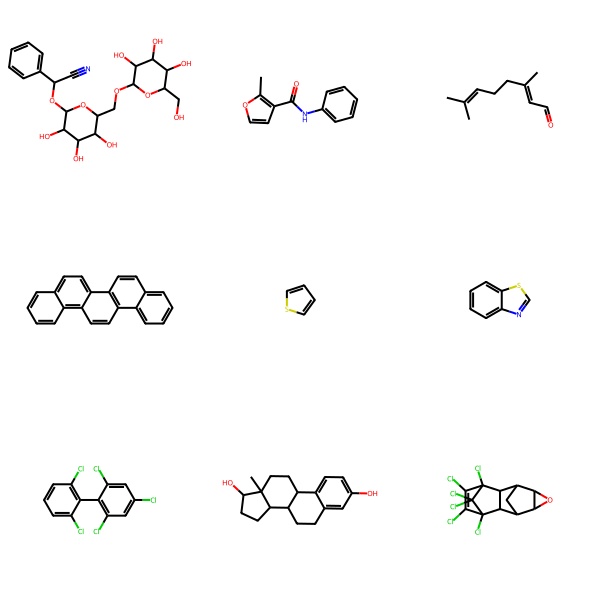

In [7]:
from rdkit import Chem
from rdkit.Chem import Draw
from itertools import islice

molecules = [Chem.MolFromSmiles(smiles) for smiles in islice(solubility_df['smiles'], 9)]
Draw.MolsToGridImage(molecules)

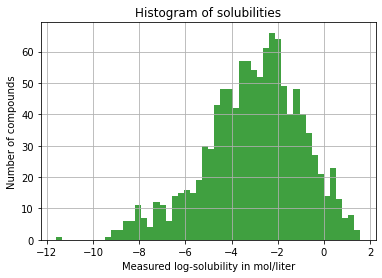

In [8]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

solubilities = np.array(solubility_df["measured log solubility in mols per litre"])
n, bins, patches = plt.hist(solubilities, 50, facecolor='green', alpha=0.75)
plt.xlabel('Measured log-solubility in mol/liter')
plt.ylabel('Number of compounds')
plt.title('Histogram of solubilities')
plt.grid(True)
plt.show()

# 5. Featurization

In [9]:
featurizer = dc.feat.CircularFingerprint(size=1024)
featurizer

CircularFingerprint[radius=2, size=1024, chiral=False, bonds=True, features=False, sparse=False, smiles=False, is_counts_based=False]

In [10]:
loader = dc.data.CSVLoader(
      tasks=["measured log solubility in mols per litre"], feature_field = "smiles",
      featurizer = featurizer)
dataset = loader.create_dataset("../input/aqueous-solubility-dataset/aqueous solubility dataset.csv")
dataset

<DiskDataset X.shape: (1128, 1024), y.shape: (1128, 1), w.shape: (1128, 1), task_names: ['measured log solubility in mols per litre']>

# 6. Split

In [11]:
# scafold splitting
splitter = dc.splits.ScaffoldSplitter()
train_dataset, valid_dataset, test_dataset = splitter.train_valid_test_split(dataset)
train_dataset

<DiskDataset X.shape: (902, 1024), y.shape: (902, 1), w.shape: (902, 1), ids: ['CC(C)=CCCC(C)=CC(=O)' 'CCCC=C' 'CCCCCCCCCCCCCC' ...
 'Nc2cccc3nc1ccccc1cc23 ' 'C1CCCCCC1' 'OC1CCCCCC1'], task_names: ['measured log solubility in mols per litre']>

In [12]:
valid_dataset

<DiskDataset X.shape: (113, 1024), y.shape: (113, 1), w.shape: (113, 1), ids: ['Nc1ncnc2nc[nH]c12 ' 'Nc1nc(O)nc2nc[nH]c12 '
 'Fc1cccc(F)c1C(=O)NC(=O)Nc2cc(Cl)c(F)c(Cl)c2F ' ...
 'OC(Cn1cncn1)(Cn2cncn2)c3ccc(F)cc3F '
 'FC(F)(F)c1cccc(c1)N2CC(CCl)C(Cl)C2=O' 'CC1(C)CON(Cc2ccccc2Cl)C1=O'], task_names: ['measured log solubility in mols per litre']>

In [13]:
test_dataset

<DiskDataset X.shape: (113, 1024), y.shape: (113, 1), w.shape: (113, 1), ids: ['c1cc2ccc3cccc4ccc(c1)c2c34' 'Cc1cc(=O)[nH]c(=S)[nH]1'
 'Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4 ' ...
 'c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43' 'Cc1occc1C(=O)Nc2ccccc2'
 'OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O '], task_names: ['measured log solubility in mols per litre']>

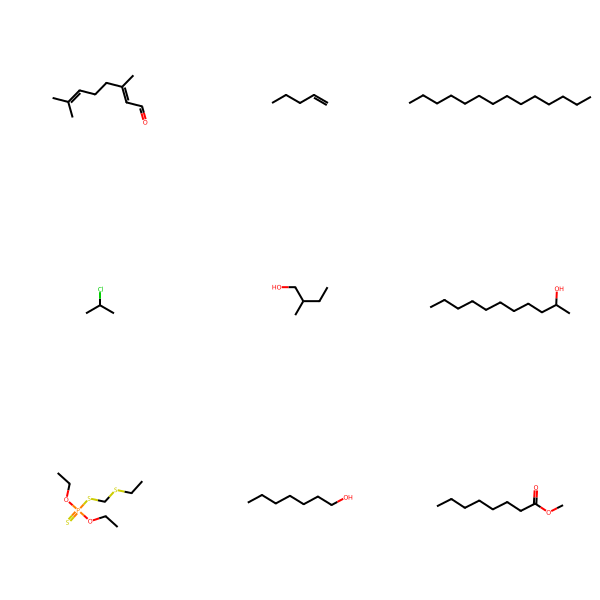

In [14]:
train_mols = [Chem.MolFromSmiles(compound) for compound in train_dataset.ids]
Draw.MolsToGridImage(train_mols[:9])

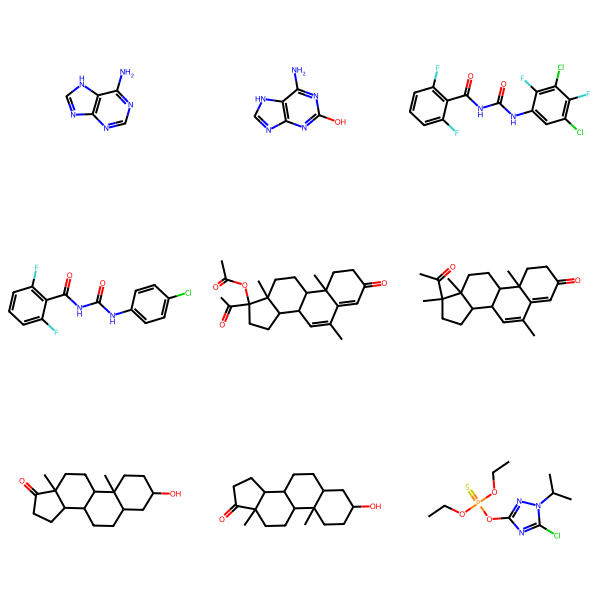

In [15]:
valid_mols = [Chem.MolFromSmiles(compound) for compound in valid_dataset.ids]
Draw.MolsToGridImage(valid_mols[:9])

In [16]:
transformers = [
    dc.trans.NormalizationTransformer(transform_y=True, dataset=train_dataset)]

for dataset in [train_dataset, valid_dataset, test_dataset]:
  for transformer in transformers:
      dataset = transformer.transform(dataset)

# 7. Modeling with Random Forest Regression  

In [17]:
from sklearn.ensemble import RandomForestRegressor

regressor = RandomForestRegressor(n_estimators=100)
model = dc.models.SklearnModel(regressor)
model.fit(train_dataset)

In [18]:
from deepchem.utils.evaluate import Evaluator

metric = dc.metrics.Metric(dc.metrics.r2_score)
evaluator = Evaluator(model, valid_dataset, transformers)
r2score = evaluator.compute_model_performance([metric])

print(r2score)

{'r2_score': 0.143650968418518}


# 8. Optimize

In [19]:
def rf_model_builder(n_estimators, max_features, model_dir):
  sklearn_model = RandomForestRegressor(
      n_estimators=n_estimators, max_features=max_features)
  return dc.models.SklearnModel(sklearn_model, model_dir)
params_dict = {
    "n_estimators": [10, 100],
    "max_features": ["auto", "sqrt", "log2", None],
}

In [20]:
optimizer = dc.hyper.GridHyperparamOpt(rf_model_builder)
best_rf, best_rf_hyperparams, all_rf_results = optimizer.hyperparam_search(params_dict, train_dataset, valid_dataset, metric)

In [21]:
rf_test_evaluator = Evaluator(best_rf, test_dataset, transformers)
rf_test_r2score = rf_test_evaluator.compute_model_performance([metric])
print("RF Test set R^2 %f" % (rf_test_r2score["r2_score"]))

RF Test set R^2 0.387351


# 9. Plot

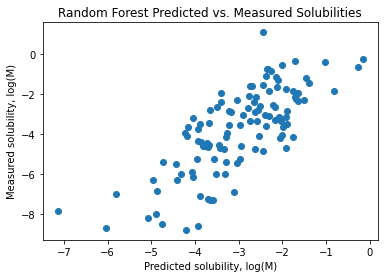

In [22]:
predicted_test = best_rf.predict(test_dataset)
measured_test = test_dataset.y

plt.scatter(predicted_test, measured_test)
plt.xlabel('Predicted solubility, log(M)')
plt.ylabel('Measured solubility, log(M)')
plt.title(r'Random Forest Predicted vs. Measured Solubilities')
plt.show()

> Reference : Getting Started with DeepChem by Richard L. Apodaca

> please refer to "Estimating Solubility from Molecular Structure" by Jay